# Flood Monitoring Data Explorer: Kingston Hogsmill

## Project purpose
This beginner project explores Environment Agency monitoring data
for Kingston Hogsmill.

The first stage identifies a monitoring station. Later stages will
download river-level readings, check data quality and produce charts.

This is a learning project, not a flood prediction system.

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Find monitoring stations
url = "https://environment.data.gov.uk/hydrology/id/stations"

params = {
    "search": "Kingston",
    "observedProperty": "waterLevel",
    "status.label": "Active"
}

response = requests.get(url, params=params)
stations = response.json()["items"]

stations_df = pd.DataFrame(stations)
print(stations_df[["label", "notation", "lat", "long"]].head())

               label                              notation        lat  \
0  Kingston Hogsmill  63b6ae06-60fc-4e92-8337-aa0e5fdd7e79  51.405763   

       long  
0 -0.302136  


## 1. Find a monitoring station

Search for an active water-level monitoring station in Kingston
and display its name, identifier and coordinates.

In [4]:
# Inspect the first station returned by the search
if stations:
    station = stations[0]

    print("Station name:", station.get("label"))
    print("Station URL:", station.get("@id"))
    print("\nAvailable station information:")

    for key, value in station.items():
        print(f"{key}: {value}")
else:
    print("No stations found. Check the station search.")

Station name: Kingston Hogsmill
Station URL: http://environment.data.gov.uk/hydrology/id/stations/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79

Available station information:
@id: http://environment.data.gov.uk/hydrology/id/stations/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79
type: [{'@id': 'http://environment.data.gov.uk/reference/def/core/SamplingLocation'}, {'@id': 'http://environment.data.gov.uk/flood-monitoring/def/core/RiverStation'}, {'@id': 'http://environment.data.gov.uk/flood-monitoring/def/core/RiverLevel'}, {'@id': 'http://environment.data.gov.uk/flood-monitoring/def/core/RiverFlow'}, {'@id': 'http://environment.data.gov.uk/flood-monitoring/def/core/Station'}]
label: Kingston Hogsmill
notation: 63b6ae06-60fc-4e92-8337-aa0e5fdd7e79
easting: 518192
northing: 168783
lat: 51.405763
long: -0.302136
riverName: Hogsmill River
stationGuid: 63b6ae06-60fc-4e92-8337-aa0e5fdd7e79
stationReference: 3390TH
wiskiID: 3390TH
RLOIid: 7266
rloiStationLink: {'@id': 'https://check-for-flooding.service.gov.uk/

In [5]:
# Display only the station's measurement information
import json

measures = station.get("measures", [])

print(json.dumps(measures, indent=2))

[
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79-level-min-86400-m-qualified",
    "parameter": "level",
    "period": 86400,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/minimum"
    }
  },
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79-level-max-86400-m-qualified",
    "parameter": "level",
    "period": 86400,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/maximum"
    }
  },
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79-level-i-900-m-qualified",
    "parameter": "level",
    "period": 900,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/instantaneous"
    }
  },
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/63b6ae06-60fc-4e92-8337-aa0e5fdd7e79-flow-i-900-m3s-qual

## 2. Download river-level readings

Download 15-minute river-level readings for Kingston Hogsmill
from 1 October to 8 October 2026 using the Environment Agency API.

In [6]:
import requests
import pandas as pd

# Kingston Hogsmill: 15-minute river-level measurements
measure_id = (
    "63b6ae06-60fc-4e92-8337-aa0e5fdd7e79"
    "-level-i-900-m-qualified"
)

readings_url = (
    "https://environment.data.gov.uk/hydrology/id/measures/"
    + measure_id
    + "/readings.json"
)

# A fixed historical period makes the analysis reproducible
params = {
    "mineq-date": "2026-10-01",
    "max-date": "2026-10-08",
    "_limit": 10000
}

response = requests.get(
    readings_url,
    params=params,
    timeout=60
)
response.raise_for_status()

readings = response.json().get("items", [])
river_raw = pd.DataFrame(readings)

print("Number of readings downloaded:", len(river_raw))
display(river_raw.head())

Number of readings downloaded: 672


,measure,date,dateTime,value,quality
0,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:00:00,0.153,Good
1,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:15:00,0.151,Good
2,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:30:00,0.150,Good
3,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:45:00,0.149,Good
4,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T01:00:00,0.144,Good


## 3. Check and clean the data

Convert timestamps to UTC and river-level values to numbers.
Check for missing values, duplicate timestamps and quality flags.
Remove records with invalid timestamps, remove duplicate timestamps,
and sort the readings in time order.

Keep missing river-level values as missing rather than replacing
them with zero.

In [7]:
if river_raw.empty:
    raise ValueError(
        "No readings returned. Check the date range before continuing."
    )

river_df = river_raw.copy()

river_df["dateTime"] = pd.to_datetime(
    river_df["dateTime"],
    utc=True,
    errors="coerce"
)

# Some readings may have no numerical value
if "value" not in river_df.columns:
    river_df["value"] = float("nan")

river_df["value"] = pd.to_numeric(
    river_df["value"],
    errors="coerce"
)

print("Rows downloaded:", len(river_df))
print("Missing values:", river_df["value"].isna().sum())

if "quality" in river_df.columns:
    print("\nQuality flags:")
    print(river_df["quality"].value_counts(dropna=False))

river_df = (
    river_df
    .dropna(subset=["dateTime"])
    .drop_duplicates(subset=["dateTime"])
    .sort_values("dateTime")
)

print("\nFirst rows after checking:")
display(river_df.head())

Rows downloaded: 672
Missing values: 0

Quality flags:
quality
Unchecked    479
Good         193
Name: count, dtype: int64

First rows after checking:


,measure,date,dateTime,value,quality
0,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01 00:00:00+00:00,0.153,Good
1,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01 00:15:00+00:00,0.151,Good
2,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01 00:30:00+00:00,0.150,Good
3,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01 00:45:00+00:00,0.149,Good
4,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01 01:00:00+00:00,0.144,Good


## 4. Plot river level over time

Create a line chart of recorded river levels at Kingston Hogsmill.
Show date and time in UTC on the horizontal axis and recorded water
level in metres on the vertical axis.

This chart shows changes in recorded water level, not flood depth,
and does not establish whether flooding occurred.

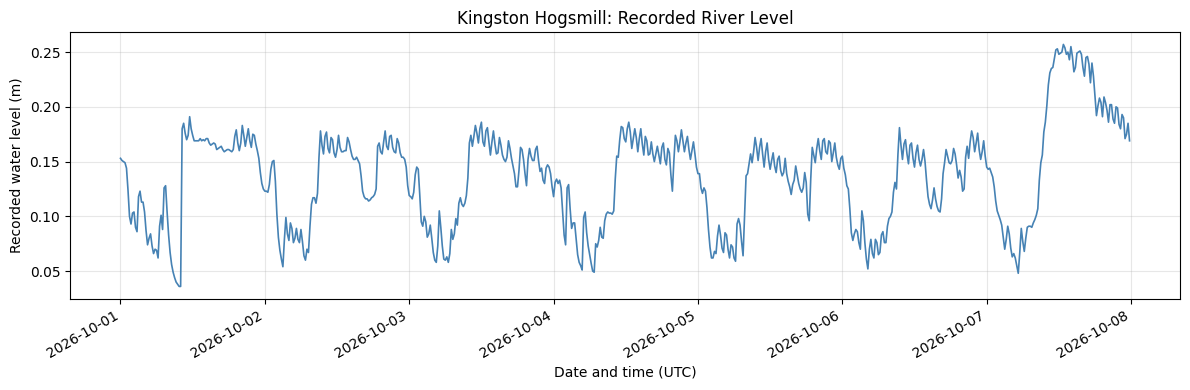

In [8]:
import matplotlib.pyplot as plt

if river_df["value"].notna().sum() == 0:
    raise ValueError("No valid water-level values are available to plot.")

fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(
    river_df["dateTime"],
    river_df["value"],
    color="steelblue",
    linewidth=1.2
)

ax.set_title("Kingston Hogsmill: Recorded River Level")
ax.set_xlabel("Date and time (UTC)")
ax.set_ylabel("Recorded water level (m)")
ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## 5. Rainfall data availability and quality checks

Searched for nearby rainfall monitoring stations.

### Hogsmill
Downloaded 672 rainfall records for each of two one-week periods
in September and October 2026.

Neither sample contained readings that were both Complete and Good
under the project's conservative filtering rule.

### Putney Heath
The API returned no rainfall readings for the requested period
from 1 October to 8 October 2026.

### Decision
Rainfall data are not used in the comparison at this stage.
Further investigation of station coverage and completeness flags
is required before extending the analysis.

In [9]:
import requests
import pandas as pd

# Search within 10 km of Kingston Hogsmill
rain_station_url = (
    "https://environment.data.gov.uk/hydrology/id/stations.json"
)

rain_search_params = {
    "observedProperty": "rainfall",
    "lat": 51.405763,
    "long": -0.302136,
    "dist": 10,
    "_limit": 100
}

rain_response = requests.get(
    rain_station_url,
    params=rain_search_params,
    timeout=60
)
rain_response.raise_for_status()

rain_stations = rain_response.json().get("items", [])

print("Rainfall stations found:", len(rain_stations))

if rain_stations:
    rain_station_table = pd.DataFrame(rain_stations)

    columns_to_show = [
        column
        for column in ["label", "notation", "lat", "long"]
        if column in rain_station_table.columns
    ]

    display(rain_station_table[columns_to_show])
else:
    print(
        "No stations found within 10 km. "
        "Try changing 'dist' from 10 to 20 and run again."
    )

Rainfall stations found: 14


,label,notation,lat,long
0,Hogsmill,a04aa8e8-45a2-4d8d-9983-7a55330693b0,51.400976,-0.284084
1,Putney Heath,0d315e9c-5acc-4cc6-a417-8d748084a8e4,51.449456,-0.224413
2,Cheam,64359f1a-fa0b-4a27-b810-d54658d0a610,51.362202,-0.210839
3,Mitcham,821f835f-2ec5-4fc1-9ff0-f1a42e3ff873,51.415955,-0.162865
4,Beddington,b6516d65-f9ca-4ad7-9c26-9c583bfc8f64,51.380391,-0.135635
5,Holland Park,72bf626d-8710-47ca-8a5c-464388561754,51.501467,-0.205419
6,Heathrow Airport,b35b1e8e-4514-4626-9a3a-effb080121d1,51.479200,-0.450620
7,Leatherhead,615a3b67-096b-47e1-b34d-a75dd217e9aa,51.288049,-0.337788
8,Norwood,ad5df79a-edad-4a84-bc68-515bca680038,51.421446,-0.108952
9,Birch Green,bdc4c2f3-8e01-4451-8608-8dd8a6f5c359,51.437409,-0.501485


In [10]:
import math
import pandas as pd

def distance_km(lat, lon):
    reference_lat = math.radians(51.405763)
    reference_lon = math.radians(-0.302136)
    lat = math.radians(float(lat))
    lon = math.radians(float(lon))

    a = (
        math.sin((lat - reference_lat) / 2) ** 2
        + math.cos(reference_lat)
        * math.cos(lat)
        * math.sin((lon - reference_lon) / 2) ** 2
    )

    return 6371 * 2 * math.asin(math.sqrt(min(1, a)))

station_rows = []

for index, item in enumerate(rain_stations):
    if item.get("lat") is not None and item.get("long") is not None:
        station_rows.append({
            "station_index": index,
            "station_name": item.get("label", "Unnamed station"),
            "distance_km": round(
                distance_km(item["lat"], item["long"]), 2
            )
        })

nearby_rain_stations = (
    pd.DataFrame(station_rows)
    .sort_values("distance_km")
    .reset_index(drop=True)
)

display(nearby_rain_stations.head(5))

,station_index,station_name,distance_km
0,0,Hogsmill,1.36
1,1,Putney Heath,7.26
2,2,Cheam,7.98
3,3,Mitcham,9.73
4,4,Beddington,11.89


In [11]:
import json

# Select Hogsmill using its station_index
rain_station = rain_stations[0]

print("Selected station:", rain_station.get("label"))
print("\nAvailable rainfall measurements:")

print(json.dumps(
    rain_station.get("measures", []),
    indent=2
))

Selected station: Hogsmill

Available rainfall measurements:
[
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/a04aa8e8-45a2-4d8d-9983-7a55330693b0-rainfall-t-900-mm-qualified",
    "parameter": "rainfall",
    "period": 900,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/total"
    }
  },
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/a04aa8e8-45a2-4d8d-9983-7a55330693b0-rainfall-t-86400-mm-qualified",
    "parameter": "rainfall",
    "period": 86400,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/total"
    }
  }
]


In [14]:
print("RAINFALL DATA CHECK")
print("Rows in original download:", len(rain_raw))
print("Rows in cleaned table:", len(rain_df))

print("\nNumerical rainfall values:")
print("Present:", rain_df["value"].notna().sum())
print("Missing:", rain_df["value"].isna().sum())
print("Equal to zero:", rain_df["value"].eq(0).sum())
print("Greater than zero:", rain_df["value"].gt(0).sum())

print("\nDate range:")
print(rain_df["dateTime"].min())
print(rain_df["dateTime"].max())

for column in ["quality", "completeness"]:
    if column in rain_df.columns:
        print(f"\n{column}:")
        print(rain_df[column].astype(str).value_counts(dropna=False))

print("\nFirst five original records:")
display(rain_raw.head())

RAINFALL DATA CHECK
Rows in original download: 672
Rows in cleaned table: 672

Numerical rainfall values:
Present: 672
Missing: 0
Equal to zero: 618
Greater than zero: 54

Date range:
2026-10-01 00:00:00+00:00
2026-10-07 23:45:00+00:00

quality:
quality
Unchecked    479
Good         193
Name: count, dtype: int64

completeness:
completeness
Incomplete    671
Complete        1
Name: count, dtype: int64

First five original records:


,measure,date,dateTime,value,valid,invalid,missing,completeness,quality
0,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:00:00,0.0,0,0,10000,Incomplete,Good
1,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:15:00,0.0,0,0,10000,Incomplete,Good
2,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:30:00,0.0,0,0,10000,Incomplete,Good
3,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T00:45:00,0.0,0,0,10000,Incomplete,Good
4,{'@id': 'http://environment.data.gov.uk/hydrol...,2026-10-01,2026-10-01T01:00:00,0.0,0,0,10000,Incomplete,Good


In [15]:
print("Total rainfall records:", len(rain_df))

print("\nCompleteness:")
print(rain_df["completeness"].value_counts(dropna=False))

print("\nQuality:")
print(rain_df["quality"].value_counts(dropna=False))

# Conservative selection for this beginner analysis:
# keep only complete, good-quality, numerical readings
usable_rain = rain_df.loc[
    rain_df["completeness"].eq("Complete")
    & rain_df["quality"].eq("Good")
    & rain_df["value"].notna()
].copy()

print("\nComplete, good-quality readings:", len(usable_rain))

Total rainfall records: 672

Completeness:
completeness
Incomplete    671
Complete        1
Name: count, dtype: int64

Quality:
quality
Unchecked    479
Good         193
Name: count, dtype: int64

Complete, good-quality readings: 0


In [24]:
import requests
import pandas as pd

print("Starting rainfall download...")

rain_measure_id = (
    "a04aa8e8-45a2-4d8d-9983-7a55330693b0"
    "-rainfall-t-900-mm-qualified"
)

rain_url = (
    "https://environment.data.gov.uk/hydrology/id/measures/"
    + rain_measure_id
    + "/readings.json"
)

rain_params = {
    "mineq-date": "2026-09-01",
    "max-date": "2026-09-08",
    "_limit": 10000
}

rain_response = requests.get(
    rain_url,
    params=rain_params,
    timeout=60
)
rain_response.raise_for_status()

rain_raw = pd.DataFrame(
    rain_response.json().get("items", [])
)

print("Rainfall readings downloaded:", len(rain_raw))

if rain_raw.empty:
    raise ValueError("No rainfall readings returned for this period.")

rain_df = rain_raw.copy()

rain_df["dateTime"] = pd.to_datetime(
    rain_df["dateTime"],
    utc=True,
    errors="coerce"
)

if "value" not in rain_df.columns:
    rain_df["value"] = float("nan")

rain_df["value"] = pd.to_numeric(
    rain_df["value"],
    errors="coerce"
)

rain_df = (
    rain_df
    .dropna(subset=["dateTime"])
    .drop_duplicates(subset=["dateTime"])
    .sort_values("dateTime")
)

print("\nCompleteness:")
print(rain_df["completeness"].value_counts(dropna=False))

print("\nQuality:")
print(rain_df["quality"].value_counts(dropna=False))

usable_rain = rain_df.loc[
    rain_df["completeness"].eq("Complete")
    & rain_df["quality"].eq("Good")
    & rain_df["value"].notna()
].copy()

print("\nComplete, good-quality readings:", len(usable_rain))


Starting rainfall download...
Rainfall readings downloaded: 672

Completeness:
completeness
Incomplete    672
Name: count, dtype: int64

Quality:
quality
Good    672
Name: count, dtype: int64

Complete, good-quality readings: 0


In [25]:
import json

# Select Putney Heath from the original search results
rain_candidate = rain_stations[1]

print("Station:", rain_candidate.get("label"))
print("\nAvailable measurements:")

print(json.dumps(
    rain_candidate.get("measures", []),
    indent=2
))

Station: Putney Heath

Available measurements:
[
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/0d315e9c-5acc-4cc6-a417-8d748084a8e4-rainfall-t-900-mm-qualified",
    "parameter": "rainfall",
    "period": 900,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/total"
    }
  },
  {
    "@id": "http://environment.data.gov.uk/hydrology/id/measures/0d315e9c-5acc-4cc6-a417-8d748084a8e4-rainfall-t-86400-mm-qualified",
    "parameter": "rainfall",
    "period": 86400,
    "valueStatistic": {
      "@id": "http://environment.data.gov.uk/reference/def/core/total"
    }
  }
]


In [26]:
import requests
import pandas as pd

print("Downloading Putney Heath rainfall...")

putney_measure_id = (
    "0d315e9c-5acc-4cc6-a417-8d748084a8e4"
    "-rainfall-t-900-mm-qualified"
)

putney_url = (
    "https://environment.data.gov.uk/hydrology/id/measures/"
    + putney_measure_id
    + "/readings.json"
)

putney_params = {
    "mineq-date": "2026-10-01",
    "max-date": "2026-10-08",
    "_limit": 10000
}

putney_response = requests.get(
    putney_url,
    params=putney_params,
    timeout=60
)
putney_response.raise_for_status()

putney_raw = pd.DataFrame(
    putney_response.json().get("items", [])
)

print("Readings downloaded:", len(putney_raw))

if putney_raw.empty:
    print("No readings returned. Do not plot this dataset.")
else:
    putney_df = putney_raw.copy()

    putney_df["dateTime"] = pd.to_datetime(
        putney_df["dateTime"],
        utc=True,
        errors="coerce"
    )

    if "value" not in putney_df.columns:
        putney_df["value"] = float("nan")

    putney_df["value"] = pd.to_numeric(
        putney_df["value"],
        errors="coerce"
    )

    putney_df = (
        putney_df
        .dropna(subset=["dateTime"])
        .drop_duplicates(subset=["dateTime"])
        .sort_values("dateTime")
    )

    print("\nCompleteness:")
    print(putney_df["completeness"].value_counts(dropna=False))

    print("\nQuality:")
    print(putney_df["quality"].value_counts(dropna=False))

    putney_usable = putney_df.loc[
        putney_df["completeness"].eq("Complete")
        & putney_df["quality"].eq("Good")
        & putney_df["value"].notna()
    ].copy()

    print(
        "\nComplete, good-quality readings:",
        len(putney_usable)
    )


Readings downloaded: 0
No readings returned. Do not plot this dataset.


## 6. Findings and limitations

### Work completed
- Identified the Kingston Hogsmill river-level monitoring station.
- Downloaded a one-week sample of 15-minute river-level readings.
- Checked timestamps, missing values, duplicates and quality flags.
- Produced a chart showing recorded river levels over time.
- Investigated rainfall-data availability and quality at nearby
  monitoring stations.

### Rainfall data checks
Hogsmill rainfall data were downloaded for one-week periods in
September and October 2026. Neither sample contained readings
that were both Complete and Good under the project's conservative
filtering rule.

Some numerical values of 0.0 were flagged as Incomplete. These
values were not interpreted as confirmed dry conditions.

Putney Heath returned no rainfall readings for the requested
October period.

Rainfall plotting and comparison with river levels are therefore
not included in this version. Further investigation of station
coverage and completeness flags is needed.

### Limitations
- This is an exploratory monitoring-data project, not a complete
  Digital Twin or a flood prediction system.
- Recorded river level is not the same as flood depth.
- The analysis does not establish whether flooding occurred.
- Checking river-level quality flags does not mean all readings
  have been validated for engineering use.
- Rainfall–river-level relationships have not been assessed.
- The project does not assess the safety of bridges, dikes or
  other infrastructure.